=== 🎯 توزیع بخش‌های مختلف مشتریان ===
Segment
Loyal Customers    169
At Risk             70
Champions           43
Lost Customers      18
Name: count, dtype: int64


C:\Users\soheil\AppData\Local\Temp\ipykernel_5920\1160653723.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_rfm, x='Segment', palette='viridis', order=['Champions', 'Loyal Customers', 'At Risk', 'Lost Customers'])


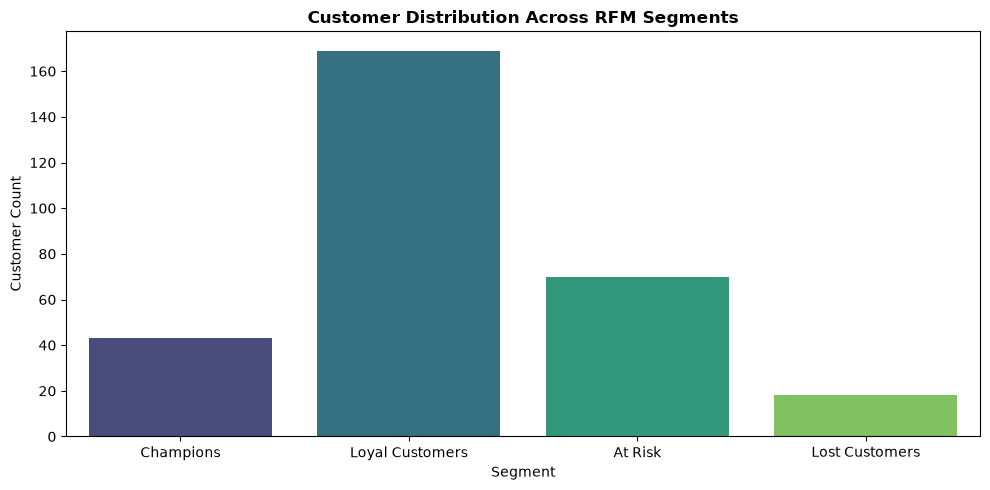

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


np.random.seed(42)
n_cust = 300

df_rfm = pd.DataFrame({
    'CustomerID': [f'CUST-{100+i}' for i in range(n_cust)],
    'Recency': np.random.randint(1, 365, size=n_cust),
    'Frequency': np.random.randint(1, 50, size=n_cust),
    'Monetary': np.random.uniform(50, 5000, size=n_cust).round(2)
})


df_rfm['R_Score'] = pd.qcut(df_rfm['Recency'], 4, labels=[4, 3, 2, 1])
df_rfm['F_Score'] = pd.qcut(df_rfm['Frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4])
df_rfm['M_Score'] = pd.qcut(df_rfm['Monetary'], 4, labels=[1, 2, 3, 4])


def segment_customer(row):
    score = int(row['R_Score']) + int(row['F_Score']) + int(row['M_Score'])
    if score >= 10:
        return 'Champions'
    elif score >= 7:
        return 'Loyal Customers'
    elif score >= 5:
        return 'At Risk'
    else:
        return 'Lost Customers'

df_rfm['Segment'] = df_rfm.apply(segment_customer, axis=1)

print("=== 🎯 توزیع بخش‌های مختلف مشتریان ===")
print(df_rfm['Segment'].value_counts())


plt.figure(figsize=(10, 5))
sns.countplot(data=df_rfm, x='Segment', palette='viridis', order=['Champions', 'Loyal Customers', 'At Risk', 'Lost Customers'])
plt.title('Customer Distribution Across RFM Segments', fontsize=12, fontweight='bold')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.show()